# Tutorial 1: Basic Connectivity Patterns

This tutorial introduces the core point-neuron connectivity patterns in `braintools.conn`. You will learn how to generate connection topologies, inspect `ConnectionResult`, attach weights and delays, and convert results to dense or sparse matrices.

The examples use the current connector API:

- call a connector with `pre_size=` and `post_size=` to get a `ConnectionResult`
- use `result.n_connections` and `result.shape` instead of counting raw arrays by hand
- use `result.weight2dense()`, `result.delay2matrix()`, and `result.weight2csr()` for matrix conversions
- use `u.math` or `u.get_mantissa()` when computing statistics or plotting data with units

---

## 1. Imports

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import brainunit as u

from braintools import conn, visualize as vis
from braintools.init import Constant, LogNormal, Normal, Uniform

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["font.size"] = 10

print("Imports successful")

Imports successful


## 2. Small Helper Functions

The `ConnectionResult.shape` property gives the flattened `(pre, post)` size even when the connector was called with tuple-shaped populations. The helpers below keep later examples compact.

In [42]:
def include_self_connections(result):
    """Infer whether a generated pattern included diagonal self-connections."""
    metadata = result.metadata
    if "allow_self_connections" in metadata:
        return metadata["allow_self_connections"]
    if "include_self_connections" in metadata:
        return metadata["include_self_connections"]
    return True


def possible_connection_count(result, include_self=None):
    """Number of possible pairs for a result's flattened shape."""
    pre_num, post_num = result.shape
    possible = pre_num * post_num
    if include_self is None:
        include_self = include_self_connections(result)
    if not include_self and pre_num == post_num:
        possible -= pre_num
    return possible


def connection_density(result, include_self=None):
    """Actual connections divided by possible connections."""
    possible = possible_connection_count(result, include_self=include_self)
    return 0.0 if possible == 0 else result.n_connections / possible


def print_result(result, max_edges=8):
    """Print the main fields of a ConnectionResult."""
    print(f"shape: {result.shape}")
    print(f"n_connections: {result.n_connections}")
    print("first edges (pre -> post):")
    for pre, post in zip(result.pre_indices[:max_edges], result.post_indices[:max_edges]):
        print(f"  {pre} -> {post}")
    print(f"weights: {None if result.weights is None else result.weights.shape}")
    print(f"delays: {None if result.delays is None else result.delays.shape}")
    print(f"metadata: {result.metadata}")


def print_quantity_stats(name, values):
    """Print statistics for plain arrays or brainunit Quantity arrays."""
    if values is None:
        print(f"{name}: None")
        return
    if u.math.size(values) == 0:
        print(f"{name}: empty")
        return
    print(f"{name} statistics:")
    print(f"  mean:   {u.math.mean(values):.3f}")
    print(f"  std:    {u.math.std(values):.3f}")
    print(f"  min:    {u.math.min(values):.3f}")
    print(f"  median: {u.math.median(values):.3f}")
    print(f"  max:    {u.math.max(values):.3f}")

---

## 3. Understanding `ConnectionResult`

All point-neuron connectors return a `ConnectionResult`. Its primary fields are:

- `pre_indices` and `post_indices`: one entry per generated edge
- `pre_size`, `post_size`, and `shape`: population sizes
- `weights` and `delays`: optional per-edge arrays, usually with `brainunit` units
- `metadata`: connector-specific parameters used to generate the result

For an unweighted topology, `weight2dense()` returns a binary dense matrix with `1` at connected pairs.

In [43]:
simple_conn = conn.Random(prob=0.1, seed=42)
result = simple_conn(pre_size=10, post_size=10)

print_result(result)
print(f"density: {connection_density(result):.1%}")

binary_matrix = result.weight2dense()
print()
print("Binary dense matrix:")
print(binary_matrix.astype(int))

shape: (10, 10)
n_connections: 12
first edges (pre -> post):
  0 -> 6
  1 -> 0
  2 -> 9
  3 -> 2
  3 -> 7
  4 -> 2
  5 -> 6
  5 -> 8
weights: None
delays: None
metadata: {'pattern': 'random', 'probability': 0.1, 'allow_self_connections': False, 'weight_initialization': None, 'delay_initialization': None}
density: 13.3%

Binary dense matrix:
[[0 0 0 0 0 0 1 0 0 0]
 [1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 1]
 [0 0 1 0 0 0 0 1 0 0]
 [0 0 1 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 0 1 0]
 [0 0 0 0 0 0 0 0 1 0]
 [0 0 1 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 1 0]]


### Caching and Resampling

Connectors cache the most recent result for the same `(pre_size, post_size, positions)` call. This avoids accidental repeated work. Pass `recompute=True` when you want a fresh sample from the same connector instance.

In [44]:
cached_again = simple_conn(pre_size=10, post_size=10)
fresh_sample = simple_conn(pre_size=10, post_size=10, recompute=True)

print(f"Second identical call returns the cached object: {cached_again is result}")
print(f"recompute=True returns the cached object: {fresh_sample is result}")
print(f"cached connections: {cached_again.n_connections}")
print(f"fresh connections:  {fresh_sample.n_connections}")

Second identical call returns the cached object: True
recompute=True returns the cached object: False
cached connections: 12
fresh connections:  8


---

## 4. Random Connectivity

`Random` creates independent Bernoulli connections with a fixed probability. `FixedProb` is a convenience alias for the same pattern.

For square same-population connectivity, self-connections are disabled by default. For rectangular cross-population connectivity, entries with equal numeric indices are kept because they do not represent a neuron connecting to itself.

In [45]:
random_conn = conn.Random(prob=0.1, seed=42)
result_random = random_conn(pre_size=100, post_size=100)

fixed_prob = conn.FixedProb(prob=0.1, seed=42)
result_fixed = fixed_prob(pre_size=100, post_size=100)

print("Random connectivity")
print(f"connections: {result_random.n_connections}")
print(f"density:     {connection_density(result_random):.2%}")
print(f"FixedProb is a Random subclass: {isinstance(fixed_prob, conn.Random)}")
print(f"same seed gives same edges: {np.array_equal(result_random.pre_indices, result_fixed.pre_indices)}")

Random connectivity
connections: 1025
density:     10.35%
FixedProb is a Random subclass: True
same seed gives same edges: True


### Effect of Connection Probability

The realized density approaches the requested probability as the number of possible pairs grows.

In [46]:
probabilities = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]
network_size = 100

print("Probability vs. realized density")
print("=" * 62)
print(f"{'probability':<14} {'connections':<14} {'density':<12} {'abs error'}")
print("=" * 62)

for prob in probabilities:
    pattern = conn.Random(prob=prob, seed=42)
    sample = pattern(pre_size=network_size, post_size=network_size)
    density = connection_density(sample)
    print(f"{prob:<14.2f} {sample.n_connections:<14} {density:<12.4f} {abs(density - prob):.4f}")

Probability vs. realized density
probability    connections    density      abs error
0.01           94             0.0095       0.0005
0.05           489            0.0494       0.0006
0.10           1025           0.1035       0.0035
0.20           2026           0.2046       0.0046
0.30           3025           0.3056       0.0056
0.50           5023           0.5074       0.0074


### Self-Connections

Use `allow_self_connections=True` for `Random` when diagonal entries should be sampled in same-size populations.

In [47]:
no_self = conn.Random(prob=0.2, allow_self_connections=False, seed=42)(pre_size=50, post_size=50)
with_self = conn.Random(prob=0.2, allow_self_connections=True, seed=42)(pre_size=50, post_size=50)
rectangular = conn.Random(prob=1.0, allow_self_connections=False, seed=42)(pre_size=5, post_size=3)

n_self = int(np.sum(with_self.pre_indices == with_self.post_indices))

print("Same-size population")
print(f"without self-connections: {no_self.n_connections}")
print(f"with self-connections:    {with_self.n_connections}")
print(f"sampled diagonal entries: {n_self}")

print()
print("Rectangular cross-population case")
print(f"5 x 3 with prob=1.0 and allow_self_connections=False: {rectangular.n_connections} connections")

Same-size population
without self-connections: 515
with self-connections:    524
sampled diagonal entries: 9

Rectangular cross-population case
5 x 3 with prob=1.0 and allow_self_connections=False: 15 connections


---

## 5. Deterministic Patterns

`AllToAll` and `OneToOne` are deterministic point-neuron patterns.

In [48]:
all_to_all = conn.AllToAll(include_self_connections=False)
result_all = all_to_all(pre_size=10, post_size=10)

all_to_all_self = conn.AllToAll(include_self_connections=True)
result_all_self = all_to_all_self(pre_size=10, post_size=10)

print("AllToAll")
print(f"without self-connections: {result_all.n_connections} / {possible_connection_count(result_all)}")
print(f"with self-connections:    {result_all_self.n_connections} / {possible_connection_count(result_all_self)}")
print(f"density without self-connections: {connection_density(result_all):.1%}")

AllToAll
without self-connections: 90 / 90
with self-connections:    100 / 100
density without self-connections: 100.0%


In [49]:
one_to_one = conn.OneToOne(circular=False)
result_equal = one_to_one(pre_size=10, post_size=10)
result_diff = one_to_one(pre_size=8, post_size=12, recompute=True)

one_to_one_circular = conn.OneToOne(circular=True)
result_circular = one_to_one_circular(pre_size=8, post_size=12)

print("OneToOne, equal sizes")
print_result(result_equal, max_edges=5)

print()
print("OneToOne, different sizes, circular=False")
print(f"connections: {result_diff.n_connections}")
print(f"pairs: {list(zip(result_diff.pre_indices, result_diff.post_indices))}")

print()
print("OneToOne, different sizes, circular=True")
print(f"connections: {result_circular.n_connections}")
print(f"pairs: {list(zip(result_circular.pre_indices, result_circular.post_indices))}")

OneToOne, equal sizes
shape: (10, 10)
n_connections: 10
first edges (pre -> post):
  0 -> 0
  1 -> 1
  2 -> 2
  3 -> 3
  4 -> 4
weights: None
delays: None
metadata: {'pattern': 'one_to_one', 'circular': False}

OneToOne, different sizes, circular=False
connections: 8
pairs: [(np.int64(0), np.int64(0)), (np.int64(1), np.int64(1)), (np.int64(2), np.int64(2)), (np.int64(3), np.int64(3)), (np.int64(4), np.int64(4)), (np.int64(5), np.int64(5)), (np.int64(6), np.int64(6)), (np.int64(7), np.int64(7))]

OneToOne, different sizes, circular=True
connections: 12
pairs: [(np.int64(0), np.int64(0)), (np.int64(1), np.int64(1)), (np.int64(2), np.int64(2)), (np.int64(3), np.int64(3)), (np.int64(4), np.int64(4)), (np.int64(5), np.int64(5)), (np.int64(6), np.int64(6)), (np.int64(7), np.int64(7)), (np.int64(0), np.int64(8)), (np.int64(1), np.int64(9)), (np.int64(2), np.int64(10)), (np.int64(3), np.int64(11))]


---

## 6. Weights and Delays

Connectors accept initializers from `braintools.init`. Bare scalars stay dimensionless; attach `brainunit` units to create physical quantities such as conductance (`u.nS`) or delay (`u.ms`).

Use `u.math` for reductions over unit-bearing values. Some NumPy reductions do not dispatch correctly for all quantity arrays.

In [50]:
constant_pattern = conn.Random(
    prob=0.1,
    weight=Constant(1.5 * u.nS),
    delay=Constant(2.0 * u.ms),
    seed=42,
)
result_constant = constant_pattern(pre_size=50, post_size=50)

print("Constant weights and delays")
print(f"connections: {result_constant.n_connections}")
print_quantity_stats("weights", result_constant.weights)
print_quantity_stats("delays", result_constant.delays)
print(f"all weights identical: {bool(u.math.all(result_constant.weights == result_constant.weights[0]))}")

Constant weights and delays
connections: 261
weights statistics:
  mean:   1.500 nS
  std:    0.000 nS
  min:    1.500 nS
  median: 1.500 nS
  max:    1.500 nS
delays statistics:
  mean:   2.000 ms
  std:    0.000 ms
  min:    2.000 ms
  median: 2.000 ms
  max:    2.000 ms
all weights identical: True


### Stochastic Initializers

In [51]:
normal_pattern = conn.Random(
    prob=0.15,
    weight=Normal(mean=1.0 * u.nS, std=0.2 * u.nS),
    delay=Normal(mean=1.5 * u.ms, std=0.3 * u.ms),
    seed=42,
)
uniform_pattern = conn.Random(
    prob=0.15,
    weight=Uniform(low=0.5 * u.nS, high=2.0 * u.nS),
    delay=Uniform(low=0.5 * u.ms, high=3.0 * u.ms),
    seed=42,
)
lognormal_pattern = conn.Random(
    prob=0.15,
    weight=LogNormal(mean=1.0 * u.nS, std=0.5 * u.nS),
    delay=Constant(1.0 * u.ms),
    seed=42,
)

result_normal = normal_pattern(pre_size=100, post_size=100)
result_uniform = uniform_pattern(pre_size=100, post_size=100)
result_lognormal = lognormal_pattern(pre_size=100, post_size=100)

for label, sample in [
    ("normal", result_normal),
    ("uniform", result_uniform),
    ("log-normal", result_lognormal),
]:
    print()
    print(f"{label} initializer")
    print(f"connections: {sample.n_connections}")
    print_quantity_stats("weights", sample.weights)
    print_quantity_stats("delays", sample.delays)


normal initializer
connections: 1526
weights statistics:
  mean:   1.005 nS
  std:    0.199 nS
  min:    0.233 nS
  median: 1.004 nS
  max:    1.675 nS
delays statistics:
  mean:   1.489 ms
  std:    0.291 ms
  min:    0.323 ms
  median: 1.488 ms
  max:    2.374 ms

uniform initializer
connections: 1526
weights statistics:
  mean:   1.261 nS
  std:    0.430 nS
  min:    0.501 nS
  median: 1.260 nS
  max:    2.000 nS
delays statistics:
  mean:   1.748 ms
  std:    0.735 ms
  min:    0.500 ms
  median: 1.728 ms
  max:    2.997 ms

log-normal initializer
connections: 1526
weights statistics:
  mean:   1.010 nS
  std:    0.497 nS
  min:    0.146 nS
  median: 0.903 nS
  max:    4.410 nS
delays statistics:
  mean:   1.000 ms
  std:    0.000 ms
  min:    1.000 ms
  median: 1.000 ms
  max:    1.000 ms


### Dense and Sparse Weight Matrices

`weight2dense()` places per-edge weights into a dense `(pre, post)` matrix. `weight2csr()` returns a `brainevent.CSR` object for sparse computations. `delay2matrix()` does the same dense conversion for delays.

In [52]:
dense_weights = result_lognormal.weight2dense()
dense_delays = result_lognormal.delay2matrix()
sparse_weights = result_lognormal.weight2csr()

print(f"dense weight matrix shape: {dense_weights.shape}")
print(f"dense delay matrix shape:  {dense_delays.shape}")
print(f"sparse matrix shape:      {sparse_weights.shape}")
print(f"sparse nonzeros:          {len(sparse_weights.indices)}")
print(f"first CSR row pointers:   {sparse_weights.indptr[:8]}")

dense weight matrix shape: (100, 100)
dense delay matrix shape:  (100, 100)
sparse matrix shape:      (100, 100)
sparse nonzeros:          1526
first CSR row pointers:   [  0  19  33  48  66  89 104 119]


### Visualizing Weight Distributions

Strip units with `u.get_mantissa()` before passing arrays to plotting functions that expect plain numbers.

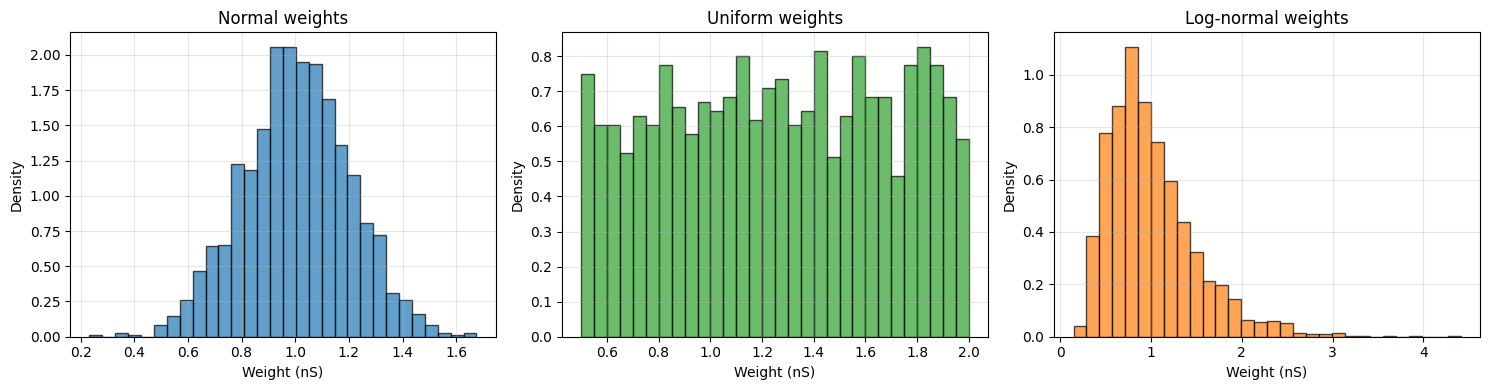

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, label, values, color in [
    (axes[0], "Normal", result_normal.weights, "tab:blue"),
    (axes[1], "Uniform", result_uniform.weights, "tab:green"),
    (axes[2], "Log-normal", result_lognormal.weights, "tab:orange"),
]:
    vis.distribution_plot(
        u.get_mantissa(values),
        bins=30,
        alpha=0.7,
        colors=[color],
        edgecolor="black",
        ax=ax,
        xlabel="Weight (nS)",
        title=f"{label} weights",
    )

plt.tight_layout()
plt.show()

---

## 7. Visualizing Connectivity

The dense conversion methods are the safest bridge from `ConnectionResult` to matrix visualizations.

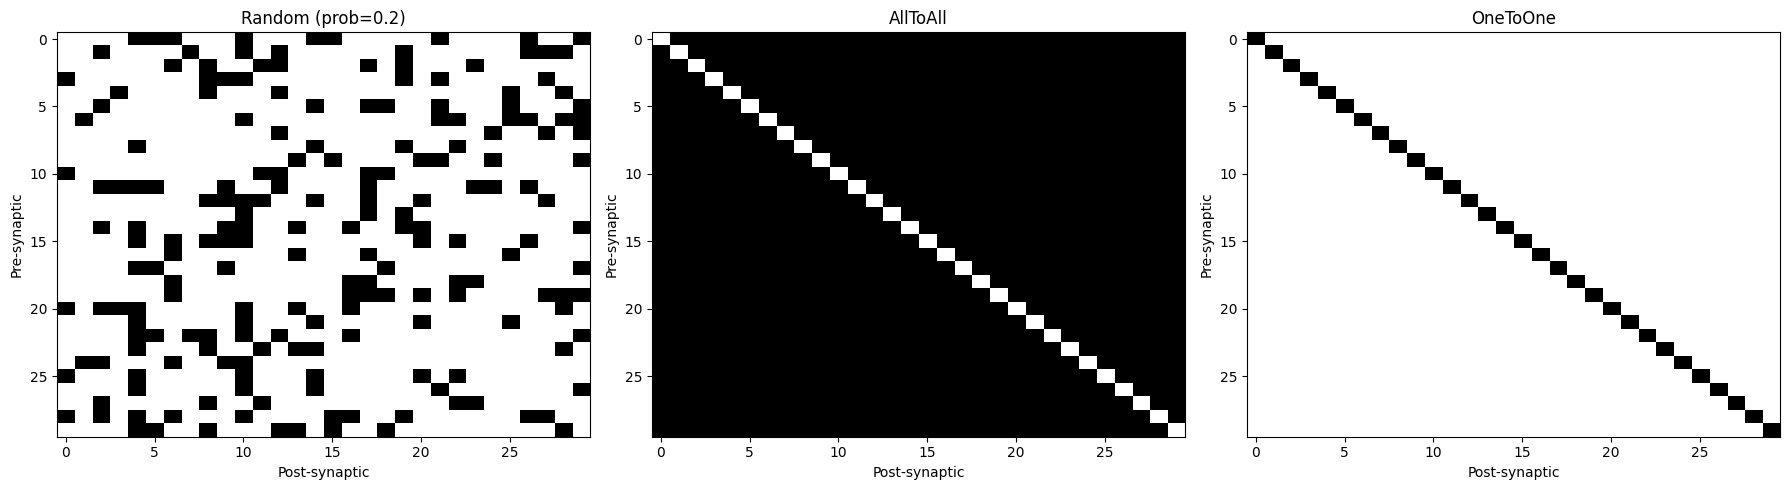

In [54]:
patterns = [
    (conn.Random(prob=0.2, seed=42), "Random (prob=0.2)"),
    (conn.AllToAll(include_self_connections=False), "AllToAll"),
    (conn.OneToOne(), "OneToOne"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (pattern, title) in zip(axes, patterns):
    sample = pattern(pre_size=30, post_size=30)
    matrix = u.get_mantissa(sample.weight2dense())
    vis.connectivity_matrix(
        matrix,
        cmap="binary",
        center_zero=False,
        show_colorbar=False,
        ax=ax,
        title=title,
    )

plt.tight_layout()
plt.show()

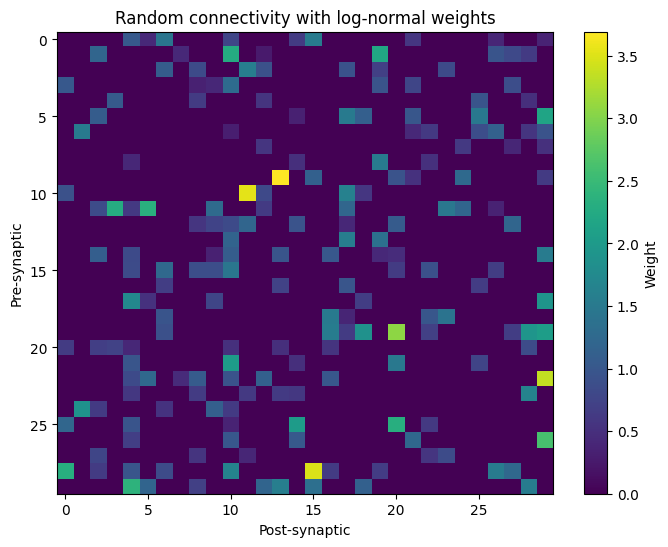

In [55]:
weighted_pattern = conn.Random(
    prob=0.2,
    weight=LogNormal(mean=1.0 * u.nS, std=0.6 * u.nS),
    seed=42,
)
weighted_result = weighted_pattern(pre_size=30, post_size=30)
weight_matrix = u.get_mantissa(weighted_result.weight2dense())

fig, ax = plt.subplots(figsize=(8, 6))
vis.connectivity_matrix(
    weight_matrix,
    cmap="viridis",
    center_zero=False,
    show_colorbar=True,
    ax=ax,
    title="Random connectivity with log-normal weights",
)
plt.show()

### Degree Distributions

The out-degree counts edges leaving each presynaptic neuron. The in-degree counts edges arriving at each postsynaptic neuron.

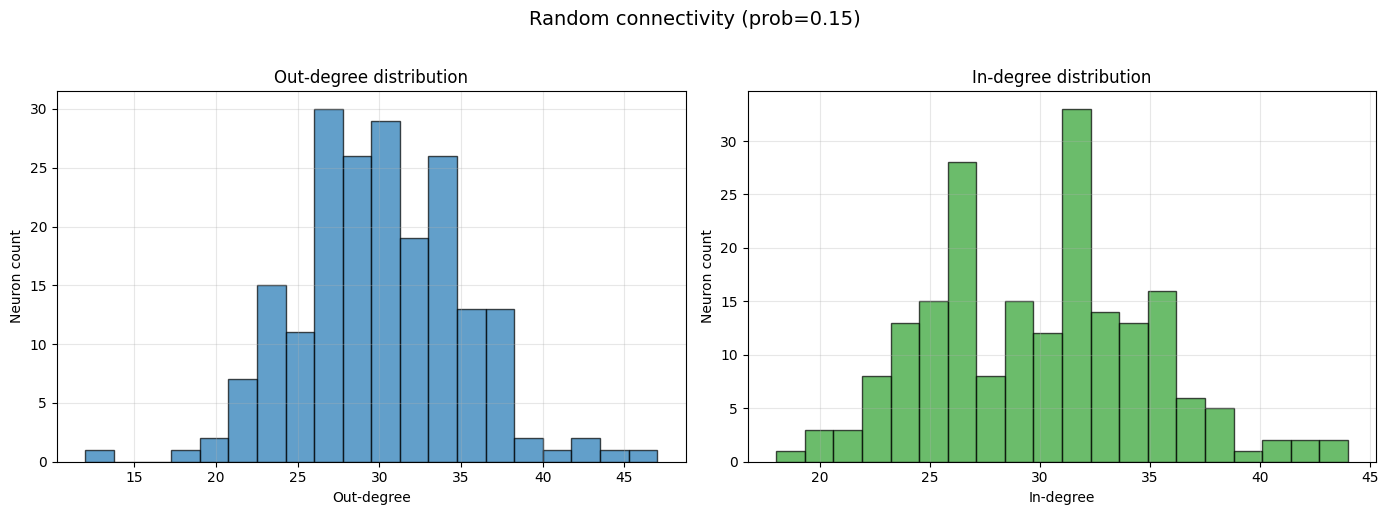

out-degree: mean=29.91, std=5.04
in-degree:  mean=29.91, std=4.92


In [56]:
degree_result = conn.Random(prob=0.15, seed=42)(pre_size=200, post_size=200)
pre_num, post_num = degree_result.shape

out_degree = np.bincount(degree_result.pre_indices, minlength=pre_num)
in_degree = np.bincount(degree_result.post_indices, minlength=post_num)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

vis.distribution_plot(
    out_degree,
    bins=20,
    density=False,
    alpha=0.7,
    colors=["tab:blue"],
    edgecolor="black",
    ax=axes[0],
    xlabel="Out-degree",
    ylabel="Neuron count",
    title="Out-degree distribution",
)
vis.distribution_plot(
    in_degree,
    bins=20,
    density=False,
    alpha=0.7,
    colors=["tab:green"],
    edgecolor="black",
    ax=axes[1],
    xlabel="In-degree",
    ylabel="Neuron count",
    title="In-degree distribution",
)

plt.suptitle("Random connectivity (prob=0.15)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print(f"out-degree: mean={np.mean(out_degree):.2f}, std={np.std(out_degree):.2f}")
print(f"in-degree:  mean={np.mean(in_degree):.2f}, std={np.std(in_degree):.2f}")

### Correlation Between Outgoing Patterns

`vis.correlation_matrix()` treats columns as features. To correlate presynaptic neurons by their outgoing target patterns, transpose the selected rows so each presynaptic neuron becomes a feature.

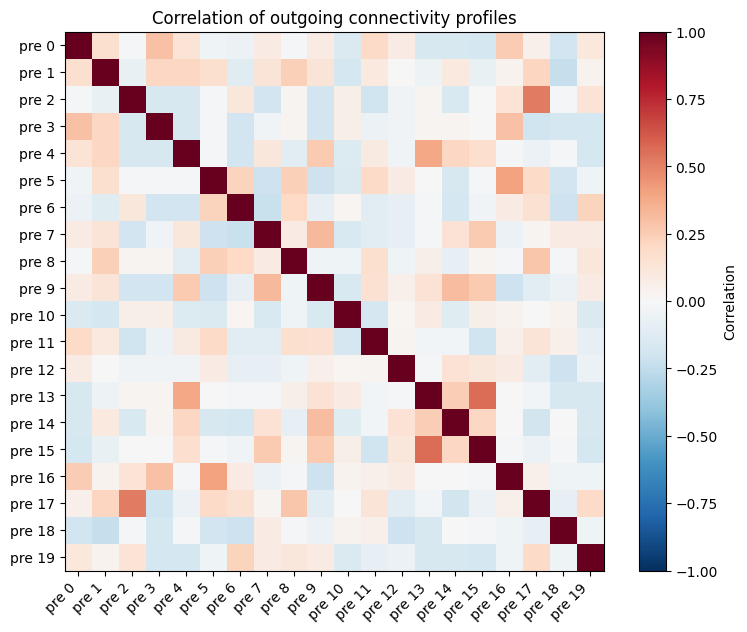

In [57]:
structured_result = conn.Random(prob=0.15, seed=42)(pre_size=50, post_size=50)
structured_matrix = u.get_mantissa(structured_result.weight2dense())

subset_size = 20
outgoing_profiles = structured_matrix[:subset_size, :].T
labels = [f"pre {i}" for i in range(subset_size)]

fig, ax = plt.subplots(figsize=(9, 7))
vis.correlation_matrix(
    outgoing_profiles,
    labels=labels,
    method="pearson",
    cmap="RdBu_r",
    show_values=False,
    ax=ax,
    title="Correlation of outgoing connectivity profiles",
)
plt.show()

---

## 8. Worked Examples

The following small utilities show common analyses built on top of `ConnectionResult`.

### 8.1 Probability for a Target Expected Edge Count

A fixed-probability connector controls the expected number of connections. For an exact target count, use a deterministic connector or post-process the sampled edges; for Bernoulli sampling, the realized count varies around the expectation.

In [58]:
def probability_for_expected_connections(
    pre_size,
    post_size,
    target_connections,
    include_self=False,
):
    """Return the Bernoulli probability for a target expected edge count."""
    pre_num = int(np.prod(pre_size)) if isinstance(pre_size, (tuple, list)) else int(pre_size)
    post_num = int(np.prod(post_size)) if isinstance(post_size, (tuple, list)) else int(post_size)
    possible = pre_num * post_num
    if not include_self and pre_num == post_num:
        possible -= pre_num
    if possible <= 0:
        return 0.0, possible
    probability = np.clip(target_connections / possible, 0.0, 1.0)
    return float(probability), possible


probability, possible = probability_for_expected_connections(100, 100, 1000)
target_sample = conn.Random(prob=probability, seed=7)(pre_size=100, post_size=100)

print(f"possible pairs:       {possible}")
print(f"target expectation:   1000")
print(f"probability:          {probability:.4f}")
print(f"realized connections: {target_sample.n_connections}")

possible pairs:       9900
target expectation:   1000
probability:          0.1010
realized connections: 1011


### 8.2 In-Degree Scaled Weights

This assigns each incoming edge to a postsynaptic neuron a weight of `base_weight / in_degree`, so every neuron with at least one input receives the same total incoming weight.

In [59]:
def create_indegree_scaled_weights(result, base_weight=1.0 * u.nS):
    """Scale each edge by the in-degree of its postsynaptic target."""
    if result.n_connections == 0:
        return np.array([]) * u.get_unit(base_weight)
    in_degree = np.bincount(result.post_indices, minlength=result.shape[1])
    return base_weight / in_degree[result.post_indices]


scaling_result = conn.Random(prob=0.1, seed=42)(pre_size=100, post_size=100)
scaled_weights = create_indegree_scaled_weights(scaling_result, base_weight=1.0 * u.nS)

total_input = np.zeros(scaling_result.shape[1])
np.add.at(total_input, scaling_result.post_indices, u.get_mantissa(scaled_weights))
connected_targets = total_input > 0

print_quantity_stats("scaled weights", scaled_weights)
print(f"connected postsynaptic neurons: {int(np.sum(connected_targets))}")
print(f"mean total input over connected targets: {np.mean(total_input[connected_targets]):.3f} nS")
print(f"std total input over connected targets:  {np.std(total_input[connected_targets]):.3f} nS")

scaled weights statistics:
  mean:   0.098 nS
  std:    0.028 nS
  min:    0.059 nS
  median: 0.091 nS
  max:    0.200 nS
connected postsynaptic neurons: 100
mean total input over connected targets: 1.000 nS
std total input over connected targets:  0.000 nS


### 8.3 Connectivity Statistics

In [60]:
def value_stats(values):
    """Return summary statistics for an optional array or Quantity."""
    if values is None or u.math.size(values) == 0:
        return None
    return {
        "mean": u.math.mean(values),
        "std": u.math.std(values),
        "min": u.math.min(values),
        "max": u.math.max(values),
    }


def reciprocal_pair_count(result):
    """Count mutual directed pairs once for square populations."""
    if result.shape[0] != result.shape[1]:
        return None
    pairs = set(zip(result.pre_indices.tolist(), result.post_indices.tolist()))
    return sum((post, pre) in pairs for pre, post in pairs if pre != post) // 2


def analyze_connectivity(result):
    """Compute common statistics for a ConnectionResult."""
    pre_num, post_num = result.shape
    out_degree = np.bincount(result.pre_indices, minlength=pre_num)
    in_degree = np.bincount(result.post_indices, minlength=post_num)
    return {
        "shape": result.shape,
        "connections": result.n_connections,
        "density": connection_density(result),
        "out_degree_mean": float(np.mean(out_degree)),
        "out_degree_std": float(np.std(out_degree)),
        "in_degree_mean": float(np.mean(in_degree)),
        "in_degree_std": float(np.std(in_degree)),
        "reciprocal_pairs": reciprocal_pair_count(result),
        "weight_stats": value_stats(result.weights),
        "delay_stats": value_stats(result.delays),
    }


stats_result = conn.Random(
    prob=0.15,
    weight=Normal(mean=1.0 * u.nS, std=0.2 * u.nS),
    delay=Constant(1.0 * u.ms),
    seed=42,
)(pre_size=100, post_size=100)

stats = analyze_connectivity(stats_result)
for key, value in stats.items():
    print(f"{key}: {value}")

shape: (100, 100)
connections: 1526
density: 0.15414141414141413
out_degree_mean: 15.26
out_degree_std: 3.195684590193469
in_degree_mean: 15.26
in_degree_std: 3.0087206583529817
reciprocal_pairs: 106
weight_stats: {'mean': Quantity(1.0047823, "nS"), 'std': Quantity(0.19920722, "nS"), 'min': Quantity(0.23266889, "nS"), 'max': Quantity(1.6754766, "nS")}
delay_stats: {'mean': Quantity(1., "ms"), 'std': Quantity(0., "ms"), 'min': Quantity(1., "ms"), 'max': Quantity(1., "ms")}


---

## 9. Key Takeaways

- `Random` and `FixedProb` generate fixed-probability Bernoulli connectivity.
- `AllToAll` and `OneToOne` provide deterministic baseline patterns.
- `ConnectionResult` exposes `n_connections`, `shape`, `weight2dense()`, `delay2matrix()`, and `weight2csr()` for downstream code.
- Use explicit connector seeds for reproducibility, and pass `recompute=True` when reusing a connector instance for a fresh draw.
- Use `u.math` for reductions over `brainunit.Quantity` values, and strip units with `u.get_mantissa()` before plotting with functions that expect plain numeric arrays.